# Multi-modal single cell analysis with bixverse

*Python port of the R vignette [Multi-modal single cell analysis with bixverse](https://gregorlueg.github.io/bixverse/articles/multi_modal_single_cells.html). Original author: Gregor Lueg.*

## Intro

This vignette walks through a multi-modal single cell workflow on a CITE-seq
data set (10x's 10k Human PBMC TotalSeq-B). The general `bixverse` philosophy
still applies: do not keep things in memory if you do not have to, keep heavy
lifting in Rust, and only round-trip to Python when the user actually needs to
look at something. The bit that changes is that there is now a second modality
hanging off the main class: Antibody-Derived Tags (ADT). ATAC is on the roadmap
but not yet wired up.

Before going further, please read the
[design choices](design_single_cell.ipynb) and the
[introductory vignette](thinking_single_cell.ipynb) if you have not already.
This vignette assumes you are comfortable with the `SingleCells` class, the
on-disk count storage, and the cells-to-keep logic.

In [1]:
import re
import tempfile
from pathlib import Path
from typing import Literal

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

import bixverse as bv
import bixverse.embed
from bixverse.params import DsbParams, MinQualityParams, NeighboursParams, WnnParams

## Loading the data

A 10x Cell Ranger H5 with multiple feature types contains both the RNA and
the ADT counts in one file, separated by `feature_type`. We peek at the
metadata first to confirm what is in there before committing to anything.

In [2]:
h5_10x_path = bv.io.download_pbmc_totalseq_data()

tempdir_10x_total_seq = tempfile.TemporaryDirectory()

### EDA

In [3]:
h5_metadata = bv.io.read_tenx_h5_metadata(h5_10x_path)

h5_metadata["feature_types"]

{'Antibody Capture': 140, 'Gene Expression': 18082}

Two feature types: gene expression and antibody capture. Good, we have both
modalities to play with.

### Loading in the RNA

The RNA goes through `SingleCellsMultiModal`, which is the same class as
`SingleCells` with extra slots for the ADT counts, the ADT cache and the WNN
integration (and, later, an ATAC connection). RNA loading and storage are
identical to the single-modal case: counts get pre-filtered, normalised,
transposed, and written to the two binary files on disk. The loader writes the
directory; we then open it as a `SingleCellsMultiModal`.

In [4]:
exp_dir = Path(tempdir_10x_total_seq.name) / "pbmc_totalseq"

bv.io.load_tenx_h5(exp_dir, h5_10x_path)

sc = bv.SingleCellsMultiModal(exp_dir)

sc.obs().head()

Step 1/3: Analysing data structure and calculating QC metrics...
  Reading 10x matrix structure (shape: 8_958 cells x 18_222 features)...
  Features after type filtering: 18_082 / 18_222
First pass - gene expression statistics:
  Processed 100% of chunks (1/1)
First pass done: 61.71ms
  Genes passing filter: 13_366 / 18_082
Second pass - cell statistics:


  Processed 100% of chunks (1/1)
Second pass done: 174.35ms
  Cells passing filter: 8_958 / 8_958
Step 2/3: QC Results:
  Genes passing QC: 13_366 / 18_222
  Cells passing QC: 8_958 / 8_958
Step 3/3: Writing cells to CSR format...
  Processing 8_958 cells in batches of 1_000...
  Processed 1_000 / 8_958 cells
  Processed 2_000 / 8_958 cells
  Processed 3_000 / 8_958 cells
  Processed 4_000 / 8_958 cells
  Processed 5_000 / 8_958 cells
  Processed 6_000 / 8_958 cells
  Processed 7_000 / 8_958 cells
  Processed 8_000 / 8_958 cells
  Processed 8_958 / 8_958 cells
  Writing complete in 194.02ms
Converting the cell-based data into the gene-based format.


  Counted 32_004_972 non-zeros over 13_366 genes in 12.79ms; converting in 1 phase(s).
  Phase 1/1: genes 0-13366, scatter 62.73ms, compress + write 93.57ms
  Conversion into gene-friendly format done: 171.39ms


cell_idx,cell_id,nnz,lib_size,to_keep
u32,str,f64,f64,bool
0,"""AAACAAGCACCATACT-1""",2499.0,4486.0,true
1,"""AAACAAGCACGTAATG-1""",2759.0,4902.0,true
2,"""AAACAAGCATGCAATG-1""",3512.0,7639.0,true
3,"""AAACAAGCATTTGGGA-1""",2973.0,5446.0,true
4,"""AAACCAATCAAGTTTC-1""",4419.0,13000.0,true


### Loading in the ADT counts

The ADT design philosophy differs from RNA. Protein panels are tiny: dozens of
antibodies, sometimes a couple of hundred for the larger commercial panels.
The cost-benefit calculus that justifies the on-disk binary format for RNA
just does not hold here. Even a million cells times 200 proteins fits in
memory without breaking a sweat. So the whole `AdtCounts` object (raw counts,
normalised counts, a bit of metadata) lives in memory as a plain matrix. The
saving is in code complexity rather than RAM.

For normalisation, you currently have two options:

- **CLR** (centred log-ratio): the Seurat default. Comes in two flavours via
  `seurat_clr`: the original CLR (allows negatives) and the modified
  Seurat-style version (does not).
- **DSB** (denoised and scaled by background): from
  [Mulè et al., 2022](https://www.nature.com/articles/s41467-022-29356-8).
  More principled if you have empty droplets to estimate the protein
  background; falls back to a 2-component k-means on log counts if you do
  not (the "ModelNegativeADTnorm" path).

Isotype controls help DSB tease apart per-cell technical noise from true
biological signal. This panel names them `Isotype_*`, so a case-insensitive
regex on "isotype" finds them; for anything unusual just pass the feature ids
directly via `isotype_names`.

There is no ADT reader for 10x h5 files in Python yet (`read_tenx_h5_adt`), so
we load the antibody capture modality into its own small store with the QC
filters off and pull the dense raw counts out of it. Same barcodes as the RNA,
140 proteins.

In [5]:
adt_sc = bv.io.load_tenx_h5(
    Path(tempdir_10x_total_seq.name) / "adt",
    h5_10x_path,
    feature_type="Antibody Capture",
    qc=MinQualityParams(min_unique_genes=0, min_lib_size=0, min_cells=0),
)

adt_counts = bv.get_counts(adt_sc).scipy_csr().toarray()
adt_barcodes = adt_sc.cell_ids()
adt_features = adt_sc.gene_ids().tolist()

iso = [f for f in adt_features if re.search("isotype", f, re.IGNORECASE)]

print(f"ADT counts: {adt_counts.shape[0]} cells x {adt_counts.shape[1]} proteins")
print(f"isotypes: {iso}")

Step 1/3: Analysing data structure and calculating QC metrics...
  Reading 10x matrix structure (shape: 8_958 cells x 18_222 features)...
  Features after type filtering: 140 / 18_222
First pass - gene expression statistics:
  Processed 100% of chunks (1/1)
First pass done: 63.41ms
  Genes passing filter: 140 / 140
Second pass - cell statistics:
  Processed 100% of chunks (1/1)
Second pass done: 86.19ms
  Cells passing filter: 8_958 / 8_958
Step 2/3: QC Results:
  Genes passing QC: 140 / 18_222
  Cells passing QC: 8_958 / 8_958
Step 3/3: Writing cells to CSR format...
  Processing 8_958 cells in batches of 1_000...
  Processed 1_000 / 8_958 cells
  Processed 2_000 / 8_958 cells
  Processed 3_000 / 8_958 cells


  Processed 4_000 / 8_958 cells
  Processed 5_000 / 8_958 cells
  Processed 6_000 / 8_958 cells
  Processed 7_000 / 8_958 cells
  Processed 8_000 / 8_958 cells
  Processed 8_958 / 8_958 cells
Converting the cell-based data into the gene-based format.
  Writing complete in 84.20ms


  Counted 1_103_903 non-zeros over 140 genes in 884.21µs; converting in 1 phase(s).
  Phase 1/1: genes 0-140, scatter 2.25ms, compress + write 2.67ms
  Conversion into gene-friendly format done: 6.37ms
ADT counts: 8958 cells x 140 proteins
isotypes: ['Isotype_MOPC.21', 'Isotype_MOPC.173', 'Isotype_MPC.11', 'Isotype_RTK4530', 'Isotype_RTK2071', 'Isotype_RTK2758']


In [6]:
bv.mm.add_adt_counts(
    sc,
    adt_counts,
    adt_barcodes,
    adt_features,
    method="dsb",
    dsb_params=DsbParams(
        use_isotype_controls=True,
        quantile_low=0.01,
        quantile_high=1.0,
    ),
    isotype_names=iso,
)

sc

DSB: estimating per-protein background via k-means (no empty drops)
DSB: Step II - estimating per-cell background


SingleCellsMultiModal(
  dir='/var/folders/l0/d50zd8812jg94mhtl8t2swfc0000gn/T/tmpnb3kx8mj/pbmc_totalseq',
  cells=8958 (kept 8958), genes=13366,
  hvg=False, pca=False, embeddings=none,
  knn=False, graph=False, magic=False, residuals=False,
  stale=none
  adt=AdtCounts(n_cells=8958, n_proteins=140, type='DSB'), adt_pca=False, adt_knn=False, adt_graph=False,
  adt_embeddings=none, wnn=False
)

## QC

### Low quality cells

QC runs jointly across modalities. The RNA loader already populated
`lib_size` and `nnz` on the obs table; `add_adt_counts` added `adt_lib_size`
and `adt_nnz` on top. We feed all four into MAD-based outlier detection.
Two-sided is sensible across the board: extremely high ADT library size can
also flag doublets or aggregates, not just dead cells.

296 of 8958 cells flagged


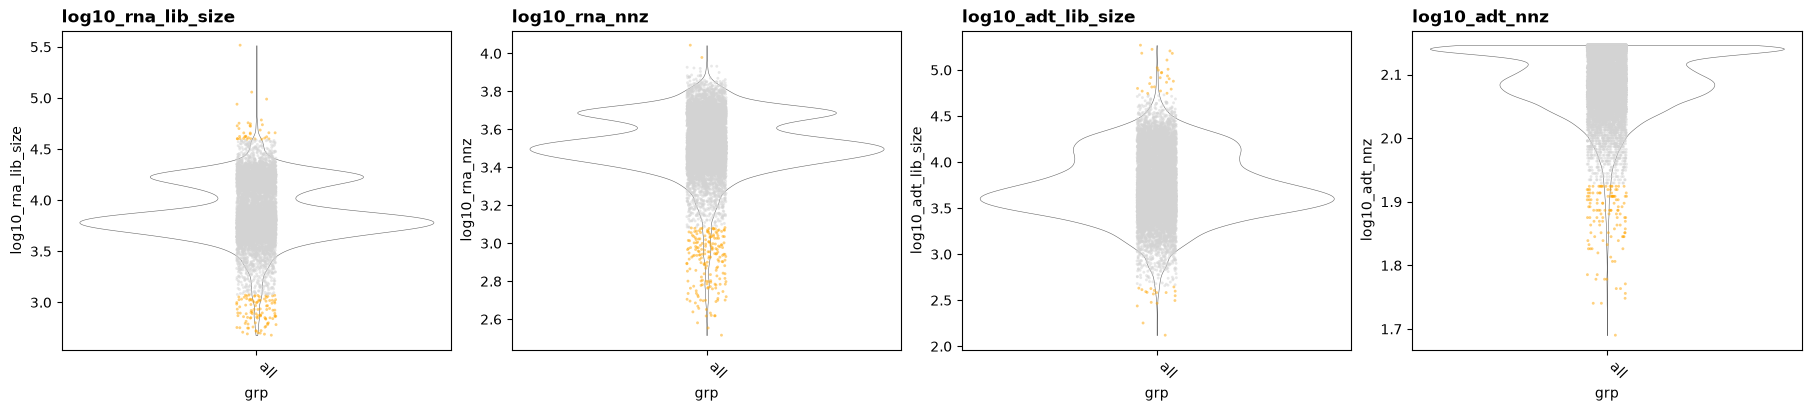

In [7]:
qc_df = sc.obs(
    cols=["cell_id", "lib_size", "nnz", "adt_lib_size", "adt_nnz"], filtered=True
)

metrics = {
    "log10_rna_lib_size": np.log10(qc_df["lib_size"].to_numpy()),
    "log10_rna_nnz": np.log10(qc_df["nnz"].to_numpy()),
    "log10_adt_lib_size": np.log10(qc_df["adt_lib_size"].to_numpy()),
    "log10_adt_nnz": np.log10(qc_df["adt_nnz"].to_numpy()),
}

directions: dict[str, Literal["twosided", "below", "above"]] = dict.fromkeys(
    metrics, "twosided"
)

qc = bv.qc.run_cell_qc(
    metrics,
    sc.cells_to_keep,
    directions=directions,
    threshold=3.0,
)

print(f"{qc.combined.sum()} of {qc.combined.size} cells flagged")

bv.pl.violin_plot(qc)
plt.show()

In [8]:
sc.add_obs(pl.DataFrame({"cell_idx": qc.cell_idx, "outlier": qc.combined}))

sc.set_cells_to_keep(qc.cell_idx[~qc.combined])

## Standard workflows

For the initial steps, the two modalities are treated independently. Each
gets its own dimensionality reduction, kNN graph, and embeddings. The
`modality` argument routes to the relevant Rust kernel and stores results in
the right cache: `sc.cache` for RNA, `sc.adt_cache` for ADT. Cross-modal
integration comes later, in the WNN section.

### RNA

Standard recipe: HVGs, PCA, neighbours, Leiden, t-SNE.

In [9]:
bv.pp.find_hvg(sc, hvg_no=2000)

bv.pp.calculate_pca(sc, no_pcs=30)

# the data is so tiny that exhaustive kNN search is faster than building
# an approximate nearest neighbour index
bv.graph.find_neighbours(
    sc,
    no_embd_to_use=16,
    neighbours_params=NeighboursParams(knn_method="exhaustive"),
)

HVG (VST): 13_366 genes, 1 batches, 1 disk block(s)
HVG (VST): Calculated gene statistics in 27.08ms
HVG (VST): Fitted Loess in 596.88µs
HVG (VST): Standardised variance in 382.92µs (183 gene(s) re-read for the clip)
HVG (VST): Total run time -> 28.10ms
Using sparse SVD solving on scaled data on 2000 HVG.


Sparse PCA: Loaded in data in 17.69ms
Sparse PCA: finished the data preparations in 2.33ms


Sparse PCA: finished calculations in 389.88ms
Sparse PCA: total run time -> 410.01ms
Generating kNN data with exhaustive method.


Building Exhaustive index ...
... built Exhaustive index in 191.25µs
Generated Exhaustive index: 197.92µs
Querying Exhaustive index (self) ...
... queried Exhaustive index (self) in 35.12ms
Queried Exhaustive index: 35.21ms
Generating the snn graph.


Added 0 edges to reconnect components that pruning cut off.
Built the Snn { similarity: Jaccard, prune: 0.0625, rescue: true } graph: 11.30ms


In [10]:
bv.graph.find_clusters(sc)

sc.obs(filtered=True).head()

cell_idx,cell_id,nnz,lib_size,to_keep,adt_nnz,adt_lib_size,outlier,leiden_clustering
u32,str,f64,f64,bool,f64,f64,bool,i32
0,"""AAACAAGCACCATACT-1""",2499.0,4486.0,true,115.0,3007.0,false,0
1,"""AAACAAGCACGTAATG-1""",2759.0,4902.0,true,101.0,1794.0,false,6
2,"""AAACAAGCATGCAATG-1""",3512.0,7639.0,true,125.0,6316.0,false,0
3,"""AAACAAGCATTTGGGA-1""",2973.0,5446.0,true,119.0,3118.0,false,0
4,"""AAACCAATCAAGTTTC-1""",4419.0,13000.0,true,136.0,12419.0,false,1


In [11]:
bv.embed.tsne(sc, modality="rna")

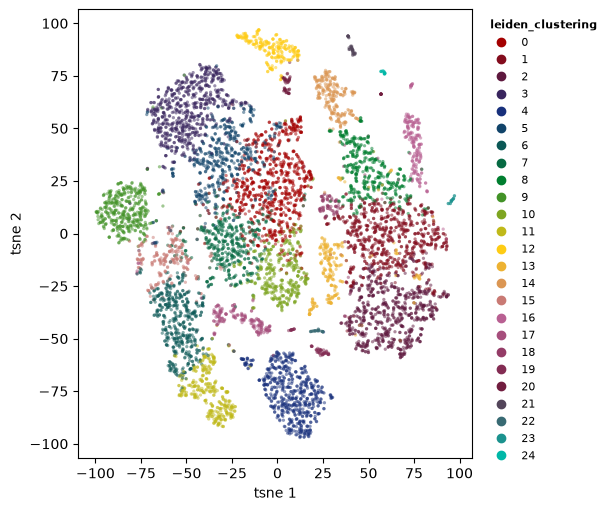

In [12]:
bv.pl.embedding_plot(
    sc,
    "tsne",
    "leiden_clustering",
    discrete=True,
    point_size=0.5,
)
plt.show()

### ADT

For ADT we skip HVG selection, there is nothing to select from in a panel of
140 antibodies, and feed the panel directly into PCA, minus the isotype
controls (they only add background noise). Otherwise the recipe is the same as
for RNA, with `modality="adt"` doing the routing.

In [13]:
adt_names = bv.mm.get_adt_names(sc)
assert adt_names is not None

bv.mm.calculate_pca_adt(
    sc,
    no_pcs=15,
    features=[f for f in adt_names if f not in iso],
)

# the data is so tiny that exhaustive kNN search is faster than building
# an approximate nearest neighbour index
bv.graph.find_neighbours(
    sc,
    neighbours_params=NeighboursParams(knn_method="exhaustive"),
    modality="adt",
)

Generating kNN data with exhaustive method.


Building Exhaustive index ...
... built Exhaustive index in 179.25µs
Generated Exhaustive index: 187.79µs
Querying Exhaustive index (self) ...
... queried Exhaustive index (self) in 21.62ms
Queried Exhaustive index: 21.71ms
Generating the snn graph.


Added 0 edges to reconnect components that pruning cut off.
Built the Snn { similarity: Jaccard, prune: 0.0625, rescue: true } graph: 10.14ms


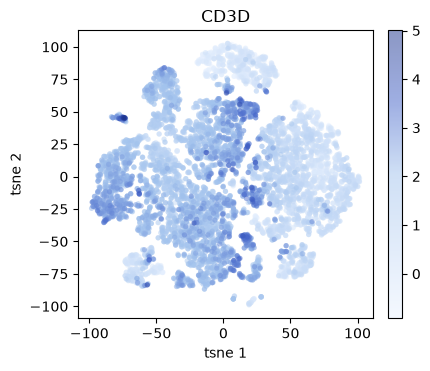

In [14]:
bv.embed.tsne(sc, modality="adt")

bv.pl.feature_plot(
    sc,
    ["CD3D"],
    "tsne",
    expr_modality="adt",
    embd_modality="adt",
    point_size=1.0,
)
plt.show()

## Plotting

`bv.pl` has a few helpers tuned to multi-modal data. The main mechanism is
that the plotting functions take an `expr_modality` (where the values come
from) and an `embd_modality` (which embedding to overlay them on) separately.
That split is what lets you colour an ADT-derived t-SNE by RNA expression, or
any other combination.

### Features against each other

The classic CITE-seq sanity check: does the protein signal match the mRNA
signal where you would expect it to? `feature_scatter_plot` takes two features
with optional `_rna` / `_adt` suffixes, so you can mix modalities freely. mRNA
tends to be sparse and noisy; ADT tends to be smoother but with more
background. A scatter against each other surfaces both effects in one picture.

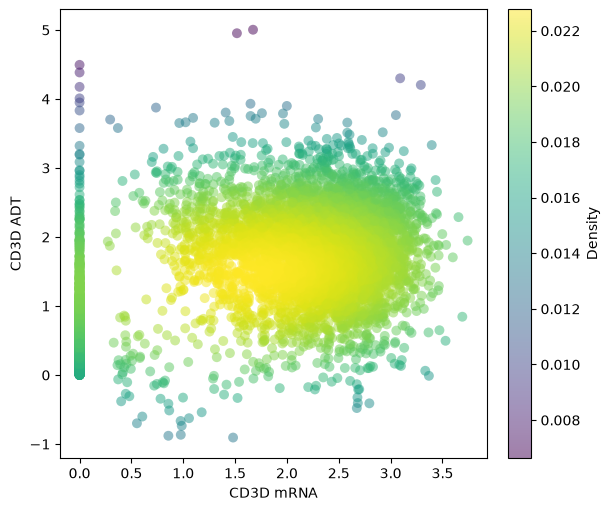

In [15]:
ax = bv.pl.feature_scatter_plot(sc, "ENSG00000167286_rna", "CD3D_adt")
ax.set_xlabel("CD3D mRNA")
ax.set_ylabel("CD3D ADT")
plt.show()

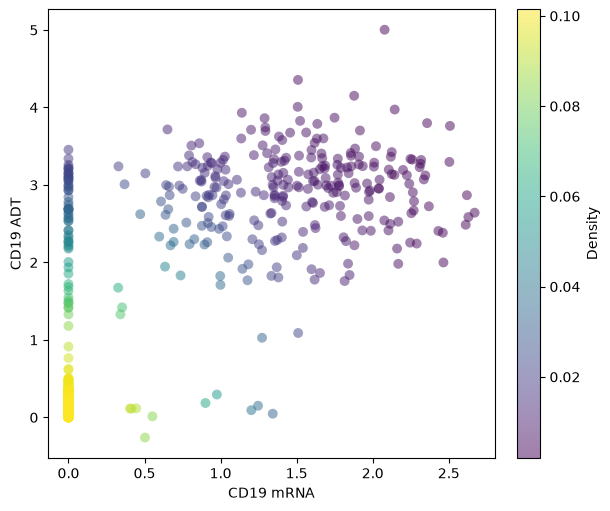

In [16]:
ax = bv.pl.feature_scatter_plot(sc, "ENSG00000177455_rna", "CD19_adt")
ax.set_xlabel("CD19 mRNA")
ax.set_ylabel("CD19 ADT")
plt.show()

### Embeddings

Same idea on the embedding side. The cell below paints RNA expression of CD3D
onto an ADT-derived t-SNE. `feature_labels` is the cleanest way to render a
human-readable label without renaming columns upstream.

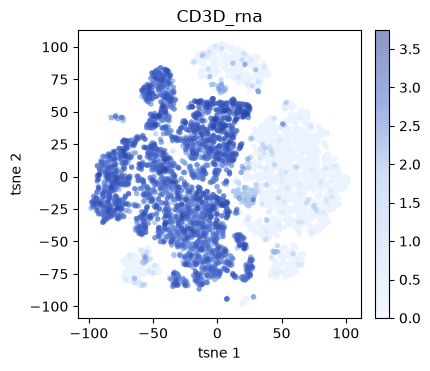

In [17]:
bv.pl.feature_plot(
    sc,
    ["ENSG00000167286"],
    "tsne",
    feature_labels={"ENSG00000167286": "CD3D_rna"},
    expr_modality="rna",
    embd_modality="adt",
    point_size=1.0,
)
plt.show()

For the reverse, ADT expression on the same ADT embedding, features just go by
their panel name:

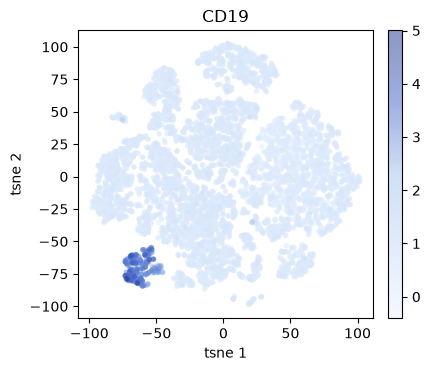

In [18]:
bv.pl.feature_plot(
    sc,
    ["CD19"],
    "tsne",
    expr_modality="adt",
    embd_modality="adt",
    point_size=1.0,
)
plt.show()

`embedding_plot` accepts the same `embd_modality` argument when you want to
overlay obs columns (clusters, donor IDs, cell type calls) on a particular
modality's embedding:

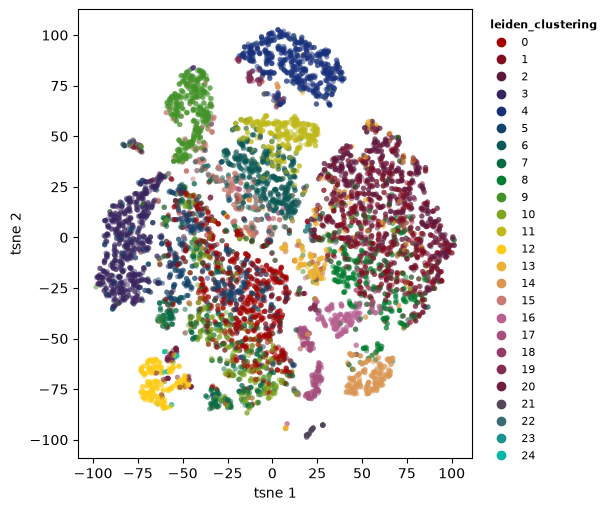

In [19]:
bv.pl.embedding_plot(
    sc,
    "tsne",
    "leiden_clustering",
    embd_modality="adt",
    discrete=True,
    point_size=1.0,
)
plt.show()

## WNN

So far we have looked at each modality in isolation. For a single cell type
assignment that uses both, you want a joint representation. The current
implementation in `bixverse` is Weighted Nearest Neighbours (WNN) from
[Hao et al., 2021](https://www.cell.com/cell/fulltext/S0092-8674(21)00583-3),
the same method Seurat v4 introduced.

The intuition is that different modalities carry different information for
different cells. For something like monocyte versus B cell, the RNA signal
is very strong. For CD4 versus CD8 T cell subsets, the protein signal is
much cleaner: the mRNAs are barely differential at that resolution. WNN
formalises this: for each cell, it asks how well that cell's neighbours in
one modality predict its profile in the *other* modality, and uses the
answer to weight the two modalities per cell. The weighted neighbours are
then merged into a single joint graph.

The whole thing runs in Rust (per-cell weights, neighbour selection, graph
merging), so it scales to hundreds of thousands of cells comfortably. The
resulting graph lands in `sc.wnn` and can be embedded just like any other
modality.

In [20]:
bv.mm.generate_wnn_graph(sc, wnn_params=WnnParams(sd_scale=1.0))

bv.mm.get_wnn_weights(sc).head()

Running WNN graph generation.


Running the kNN generation for modality 1 with 200 neighbours.
Running the kNN generation for modality 2 with 200 neighbours.
Built the Snn { similarity: Jaccard, prune: 0.0, rescue: false } graph: 13.08ms
Built the Snn { similarity: Jaccard, prune: 0.0, rescue: false } graph: 11.61ms
WNN: per-modality SNN built in 25.34ms
WNN: modality weights in 7.45ms
WNN: graph constructed in 15.80ms
Generating the snn graph.


Added 0 edges to reconnect components that pruning cut off.
Built the Snn { similarity: Jaccard, prune: 0.0625, rescue: true } graph: 13.51ms


cell_id,weight_modality_1,weight_modality_2
str,f64,f64
"""AAACAAGCACCATACT-1""",0.348767,0.651233
"""AAACAAGCACGTAATG-1""",0.287499,0.712501
"""AAACAAGCATGCAATG-1""",0.08311,0.91689
"""AAACAAGCATTTGGGA-1""",0.381643,0.618356
"""AAACCAATCAAGTTTC-1""",0.585926,0.414074


In [21]:
bv.embed.tsne(sc, modality="wnn")

A nice sanity check is to look at the same marker from both modalities,
projected onto the WNN embedding. If WNN is doing its job, the two pictures
should largely agree, even though they come from completely independent
measurements.

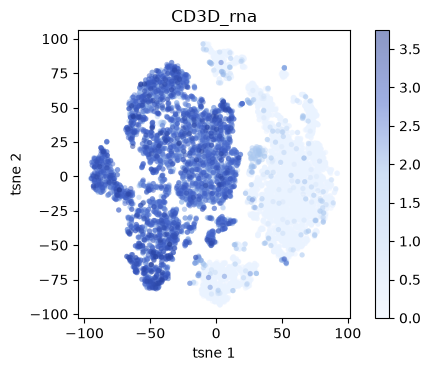

In [22]:
bv.pl.feature_plot(
    sc,
    ["ENSG00000167286"],
    "tsne",
    feature_labels={"ENSG00000167286": "CD3D_rna"},
    expr_modality="rna",
    embd_modality="wnn",
    point_size=1.0,
)
plt.show()

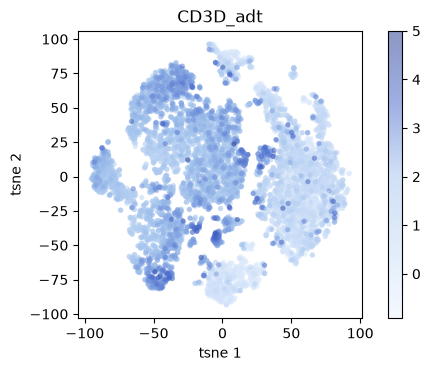

In [23]:
bv.pl.feature_plot(
    sc,
    ["CD3D"],
    "tsne",
    feature_labels={"CD3D": "CD3D_adt"},
    expr_modality="adt",
    embd_modality="wnn",
    point_size=1.0,
)
plt.show()

From here, the rest of the pipeline (clustering, marker detection, cell type
annotation) works exactly as in the [standard vignette](pbmc_single_cell.ipynb):
just point the relevant functions at the WNN graph with `modality="wnn"`
instead of the RNA one.

## Clean up

In [24]:
tempdir_10x_total_seq.cleanup()